# Vector NSI with NeutrinoVectorNSI.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/NeutrinoVectorNSI.jl/blob/main/notebooks/01_vector_NSI.ipynb)

Neutral-current non-standard interactions (NSI) of neutrinos with electrons and quarks change the matter potential that neutrinos feel on their way through the Earth. In the flavour basis the Hamiltonian becomes

$$H = \frac{1}{2E}\,U\,\mathrm{diag}(0, \Delta m^2_{21}, \Delta m^2_{31})\,U^\dagger + V\left[\begin{pmatrix}1&0&0\\0&0&0\\0&0&0\end{pmatrix} + \varepsilon\right], \qquad V = \sqrt2\,G_F N_e,$$

with $\varepsilon$ a Hermitian matrix: real diagonal entries $\varepsilon_{\alpha\alpha}$ and complex off-diagonal ones $\varepsilon_{\alpha\beta} = |\varepsilon_{\alpha\beta}|\,e^{i\delta\varepsilon_{\alpha\beta}}$.

NeutrinoVectorNSI.jl adds this to [GLoBES.jl](https://github.com/JuliaNeutrino/GLoBES.jl) as a *propagation block*. GLoBES.jl builds a probability engine from the block. Its probabilities, event rates, χ² and fits then treat the ε's like any other oscillation parameter. This notebook goes through the package and shows what vector NSI do at DUNE and in atmospheric neutrinos.

In [ ]:
# Install GLoBES.jl and NeutrinoVectorNSI.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/NeutrinoVectorNSI.jl")
Pkg.add("Plots")

In [1]:
using GLoBES, NeutrinoVectorNSI, Plots
paper_theme!()   # Plots defaults for publication figures

## The whole package

A block is a subtype of `GLoBES.PropagationBlock` with a few methods. `VectorNSI` says which parameters it has (`block_parameters`), their ASCII spellings (`parameter_aliases`) and what it adds to the matter term ε (`matter_correction!`). The helpers `flavour_pairs`, `coupling_parameters` and `add_couplings!` come from GLoBES.jl and are shared with NeutrinoScalarNSI.jl. This is the entire source:

In [2]:
print(read(pathof(NeutrinoVectorNSI), String))

"""
Vector (neutral-current) non-standard neutrino interactions with matter for
GLoBES.jl, as a propagation block that combines with the other blocks in
`NewPhysics`.
"""
module NeutrinoVectorNSI

using GLoBES
using GLoBES:
    PropagationBlock,
    flavour_pairs,
    pair_label,
    coupling_parameters,
    coupling_aliases,
    add_couplings!
import GLoBES: block_parameters, parameter_aliases, matter_correction!

export VectorNSI

"""
    VectorNSI(couplings...)

Neutral-current (vector) non-standard interactions with matter: the matter
term of the Hamiltonian becomes V [diag(1, 0, 0) + ε], with ε Hermitian in
units of the standard potential V = √2 G_F N_e (so ε_αβ is the effective
coupling to electrons, ε = Σ_f (N_f/N_e) ε^f).

Couplings are flavour pairs (`:ee`, `:eμ`, `:eτ`, `:μμ`, `:μτ`, `:ττ`, or
ASCII `:emu`, ...; all six by default). Parameters: `ε_αβ` and, off the
diagonal, the phase `δε_αβ` (ASCII `eps_etau`, `deltaeps_etau`, ...).

```julia
VectorNSI(:ee, :eτ)   # couplings

`NewPhysics` turns blocks into a model. Each flavour pair gives a modulus `ε_αβ`; the off-diagonal pairs also give a phase `δε_αβ`:

In [3]:
model = NewPhysics(VectorNSI())   # all six couplings
model.names

9-element Vector{Symbol}:
 :ε_ee
 :ε_eμ
 :δε_eμ
 :ε_eτ
 :δε_eτ
 :ε_μμ
 :ε_μτ
 :δε_μτ
 :ε_ττ

In [4]:
NewPhysics(VectorNSI(:ee, :eτ)).names   # only some couplings

3-element Vector{Symbol}:
 :ε_ee
 :ε_eτ
 :δε_eτ

`use_model!` makes the model the probability engine of everything in GLoBES.jl. `OscParams(model, base; ...)` takes the standard parameters from `base` (here NuFIT 6.1, normal ordering) and sets the NSI parameters, which are zero unless given. ASCII names such as `eps_etau` work as well.

In [5]:
use_model!(model)
p = nufit_params("6.1")
sm = OscParams(model, p)
nsi = OscParams(model, p; ε_eτ = 0.2, δε_eτ = 0.0)
OscParams(model, p; eps_etau = 0.2) == nsi

true

## Appearance at DUNE

P(νμ → νe) over the 1300 km from Fermilab to SURF, for an off-diagonal ε_eτ and a diagonal ε_ee. The band shows the full range as the phase δε_eτ goes around the circle. NSI matter effects have opposite sign for antineutrinos, as the standard matter effect does.

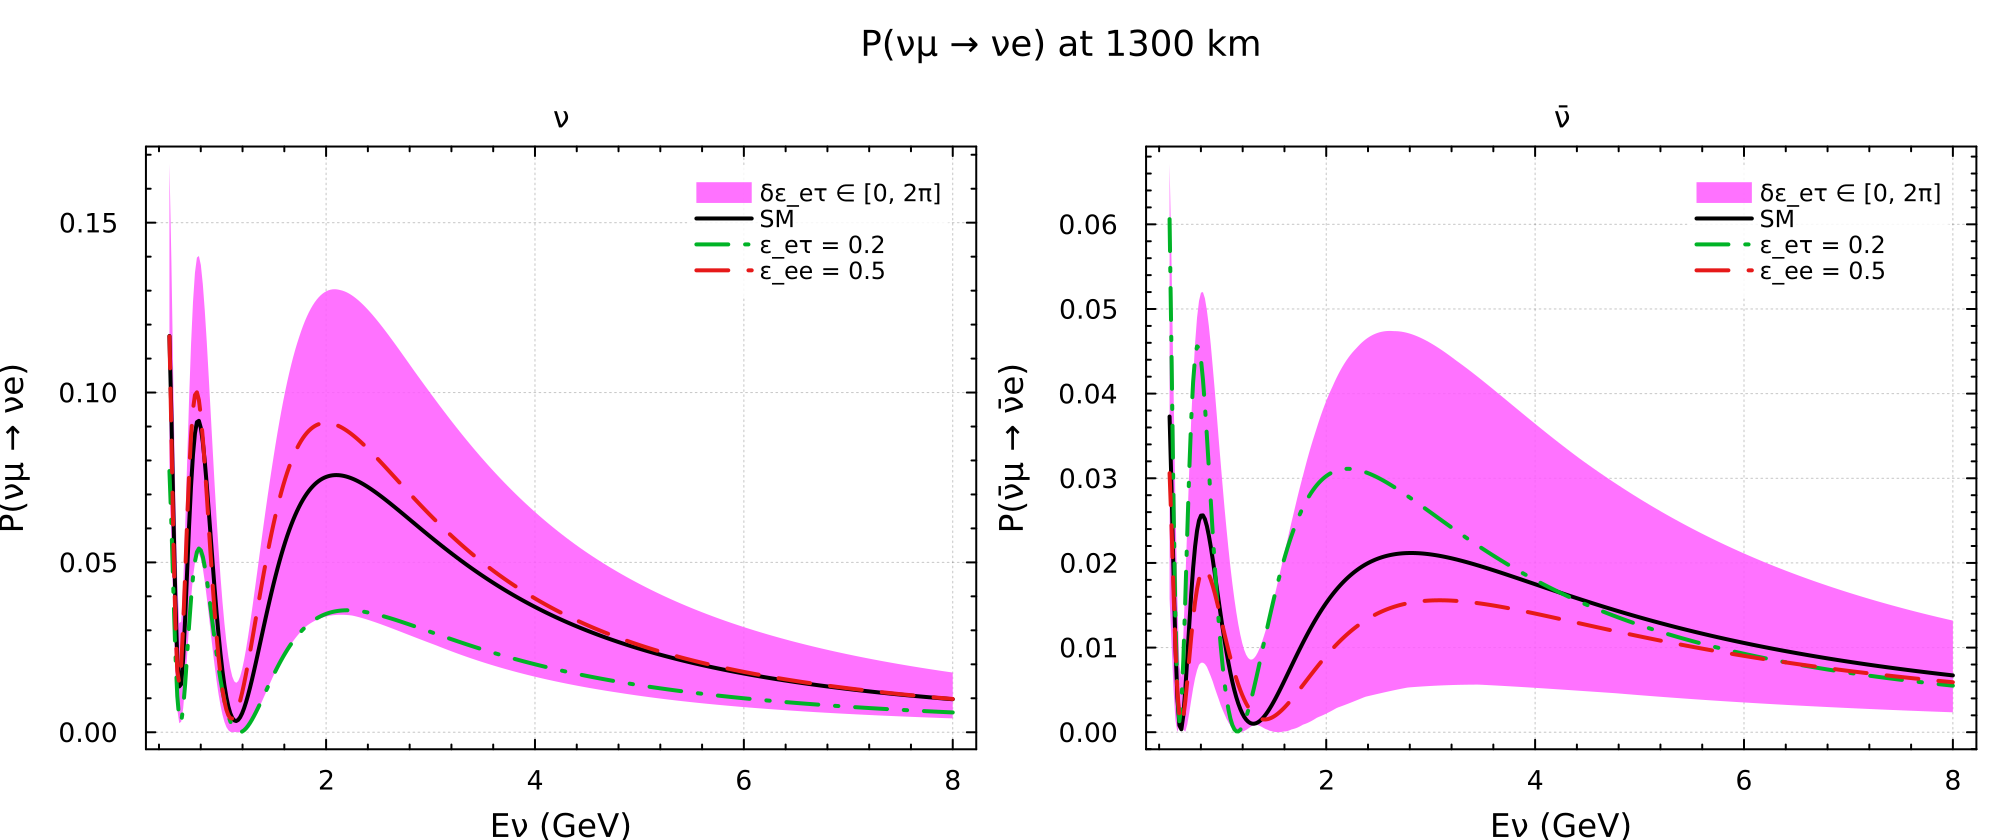

In [6]:
DUNE = (; L = 1300, ρ = 2.848)
E = range(0.5, 8, 400)
curves = ("SM" => sm, "ε_eτ = 0.2" => nsi, "ε_ee = 0.5" => OscParams(model, p; ε_ee = 0.5))
band = ("δε_eτ ∈ [0, 2π]" => (nsi, :δε_eτ => range(0, 2π, 37)),)
panel(anti) = plot_probability(curves...; E, DUNE..., antineutrino = anti, bands = band)
plot_grid([panel(false) panel(true)]; title = "P(νμ → νe) at 1300 km", column_titles = ("ν", "ν̄"), size = (1000, 420))

## Three checks on the physics

**ε_ee is a denser Earth.** A diagonal ε_ee multiplies the standard potential by 1 + ε_ee, so it should give the standard probabilities at a density 1.5 × 2.848 g/cm³:

In [7]:
Echeck = [0.5, 1.0, 2.5, 5.0]
with_nsi = probability(OscParams(model, p; ε_ee = 0.5), :μ, :e; E = Echeck, DUNE...)
standard_engine!()   # back to plain three-flavour oscillations for a moment
denser = probability(p, :μ, :e; E = Echeck, L = 1300, ρ = 1.5 * 2.848)
use_model!(model)
maximum(abs, with_nsi .- denser)

1.8596235662471372e-15

**No matter, no NSI.** At ρ = 0 every ε drops out:

In [8]:
q = OscParams(model, p; ε_eτ = 0.3, δε_eτ = 1.2, ε_μτ = 0.05, ε_ee = -0.4)
maximum(abs, probability(q, :μ, :e; E = Echeck, L = 1300, ρ = 0) .- probability(sm, :μ, :e; E = Echeck, L = 1300, ρ = 0))

0.0

**Unitarity.** NSI only change the Hamiltonian, so the probabilities still sum to one:

In [9]:
sum(probability(q, :μ, β; E = Echeck, DUNE...) for β in (:e, :μ, :τ))

4-element Vector{Float64}:
 0.9999999999999998
 0.9999999999999998
 1.0000000000000004
 1.0000000000000009

## The LMA-Dark degeneracy

Oscillation probabilities do not change when the Hamiltonian goes to $-H^*$. In vacuum this map sends $\theta_{12} \to \pi/2 - \theta_{12}$, $\delta \to \pi - \delta$ and $\Delta m^2_{31} \to -\Delta m^2_{31} + \Delta m^2_{21}$. In other words, it flips the mass ordering and puts θ12 in the "dark octant". The standard matter term $V\,\mathrm{diag}(1,0,0)$ is not invariant under the map, but NSI can make up for it: $\varepsilon_{ee} \to -\varepsilon_{ee} - 2$ and $\varepsilon_{\alpha\beta} \to -\varepsilon^*_{\alpha\beta}$ (González-García, Maltoni and Salvado; Coloma and Schwetz, arXiv:1604.05772).

So the Standard Model with normal ordering gives exactly the same probabilities as inverted ordering with θ12 > 45° and ε_ee = −2:

In [10]:
dark = OscParams(model, p; θ12 = π / 2 - p.θ12, δ = π - p.δ, Δm31 = -p.Δm31 + p.Δm21, ε_ee = -2.0)
maximum(abs(x - y) for (from, to) in ((:μ, :e), (:μ, :μ), (:e, :e), (:e, :τ)), anti in (false, true)
        for (x, y) in zip(probability(sm, from, to; E, DUNE..., antineutrino = anti), probability(dark, from, to; E, DUNE..., antineutrino = anti)))

4.107825191113079e-15

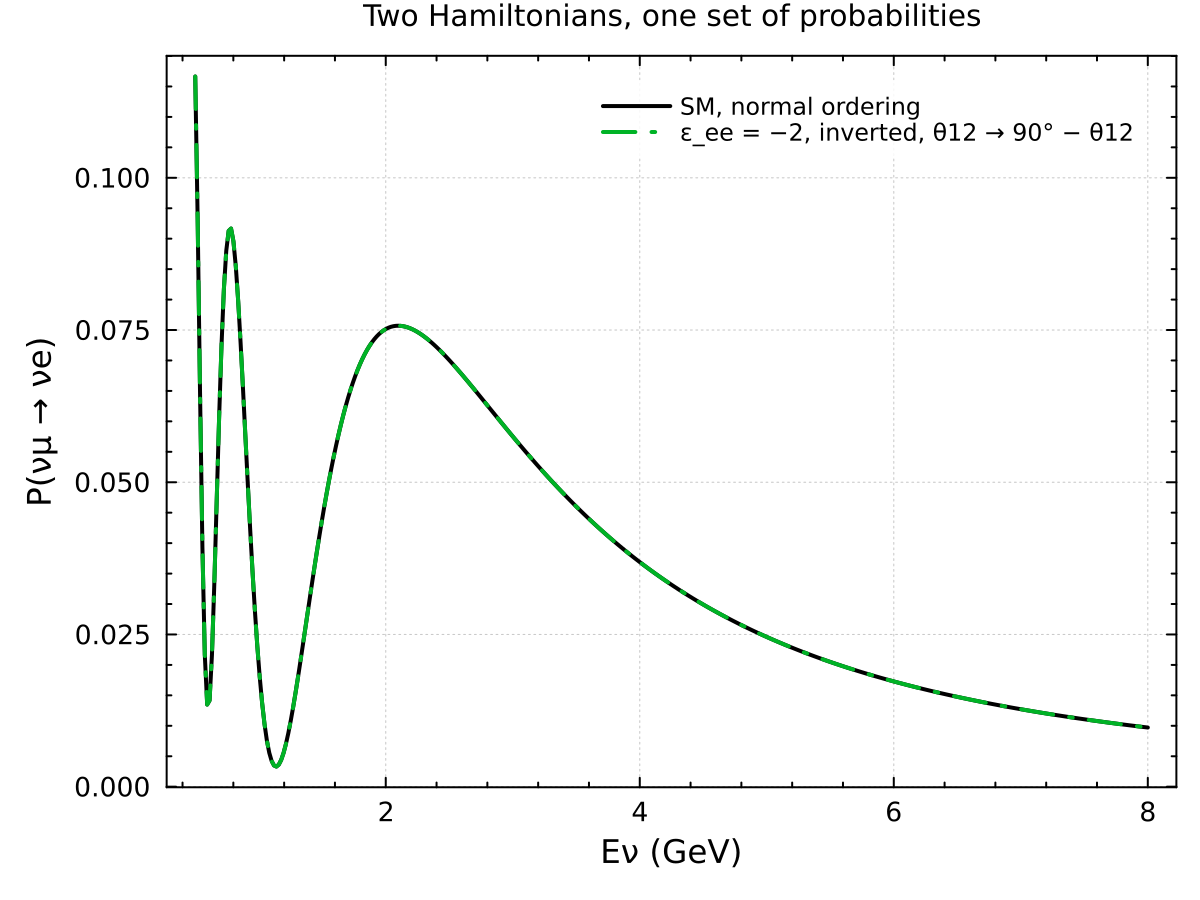

In [11]:
plot_probability("SM, normal ordering" => sm, "ε_ee = −2, inverted, θ12 → 90° − θ12" => dark; E, DUNE..., title = "Two Hamiltonians, one set of probabilities")

Both sets of curves lie on top of each other at every baseline and energy. Oscillation experiments alone cannot tell them apart. Only an experiment that measures the NSI couplings directly can break the degeneracy, such as coherent elastic neutrino–nucleus scattering (COHERENT).

## Atmospheric neutrinos and ε_μτ

The NSI potential term is $V\varepsilon$ and does not fall with energy, while the vacuum term falls as 1/E. NSI therefore matter most for high-energy neutrinos that cross a lot of matter. Atmospheric neutrinos crossing the whole Earth (L = 12 742 km) at an average density of about 5.5 g/cm³ are a good example. In P(νμ → νμ), ε_μτ shifts the position of the oscillation minimum, and its sign matters:

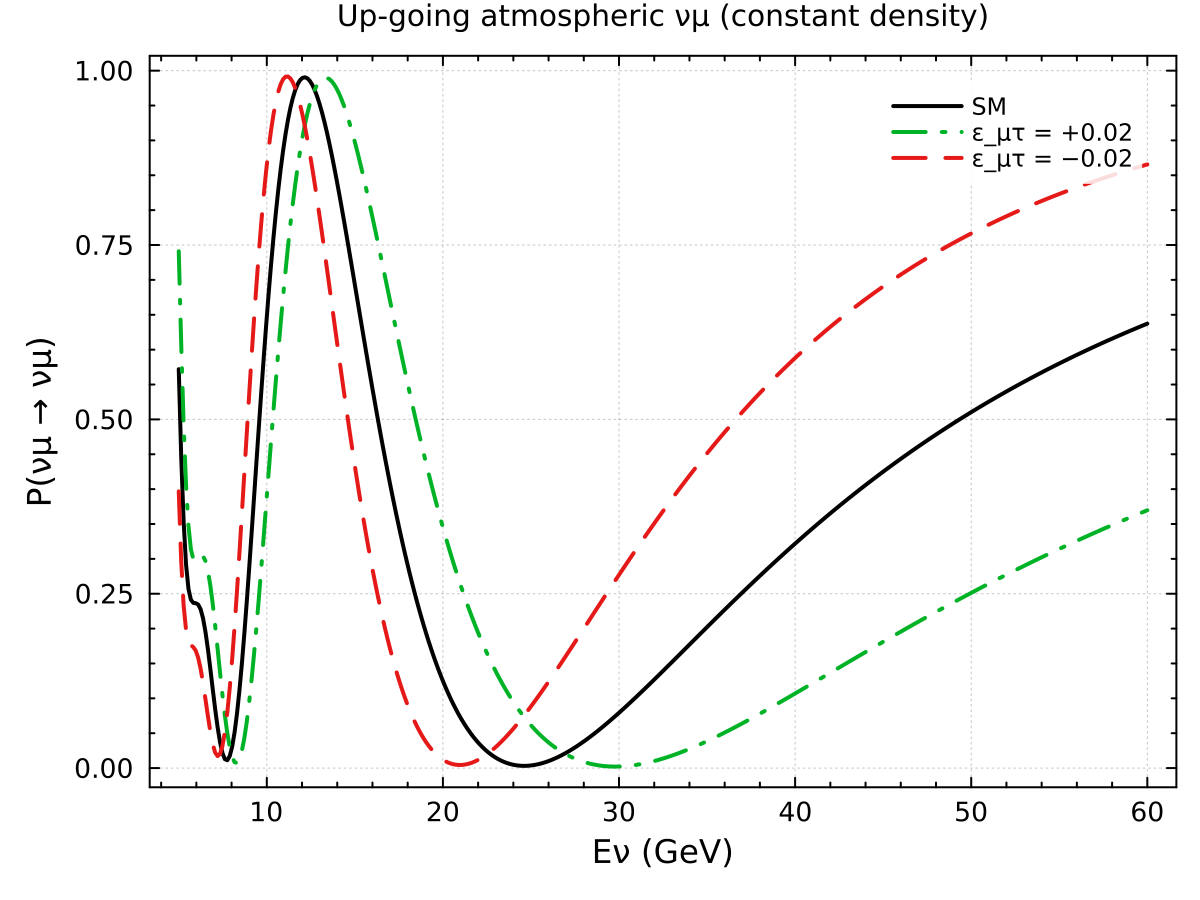

In [12]:
earth = (; L = 12_742, ρ = 5.5)
Eatm = range(5, 60, 400)
plot_probability("SM" => sm, "ε_μτ = +0.02" => OscParams(model, p; ε_μτ = 0.02), "ε_μτ = −0.02" => OscParams(model, p; ε_μτ = -0.02);
    from = :μ, to = :μ, E = Eatm, earth..., title = "Up-going atmospheric νμ (constant density)")

Here the difference from the SM grows with energy, which is how IceCube DeepCore and Super-Kamiokande measure |ε_μτ| ≲ 10⁻². At DUNE's energy and baseline the same coupling changes P(νμ → νμ) by about 20 times less:

In [13]:
ε_μτ = OscParams(model, p; ε_μτ = 0.02)
[where => maximum(abs, probability(ε_μτ, :μ, :μ; E = Ex, geometry...) .- probability(sm, :μ, :μ; E = Ex, geometry...))
 for (where, Ex, geometry) in (("DUNE", collect(E), DUNE), ("through the Earth", collect(Eatm), earth))]

2-element Vector{Pair{String, Float64}}:
              "DUNE" => 0.014025990796743715
 "through the Earth" => 0.26757220143232985

## Event rates at DUNE

The experiments of GLoBES.jl use the active model for their rates. This is the DUNE configuration of the Technical Design Report, with 5 years each of neutrino and antineutrino running:

In [14]:
dune = Experiment(dune_configuration())   # the first time, this downloads the data tables from arXiv
running_time!(dune, 5.0)
for (label, x) in curves
    simulate!(x)
    println(rpad(label, 12), round.(Int, [sum(event_rates(dune; rule = r).signal) for r in 1:4]), "   (", join(rule_names(dune), ", "), ")")
end

SM          

[1591, 321, 15380, 8953]   (nue_app, nuebar_app, numu_dis, numubar_dis)
ε_eτ = 0.2  [815, 338, 15374, 8967]   (nue_app, nuebar_app, numu_dis, numubar_dis)
ε_ee = 0.5  [1814, 280, 15356, 8948]   (nue_app, nuebar_app, numu_dis, numubar_dis)


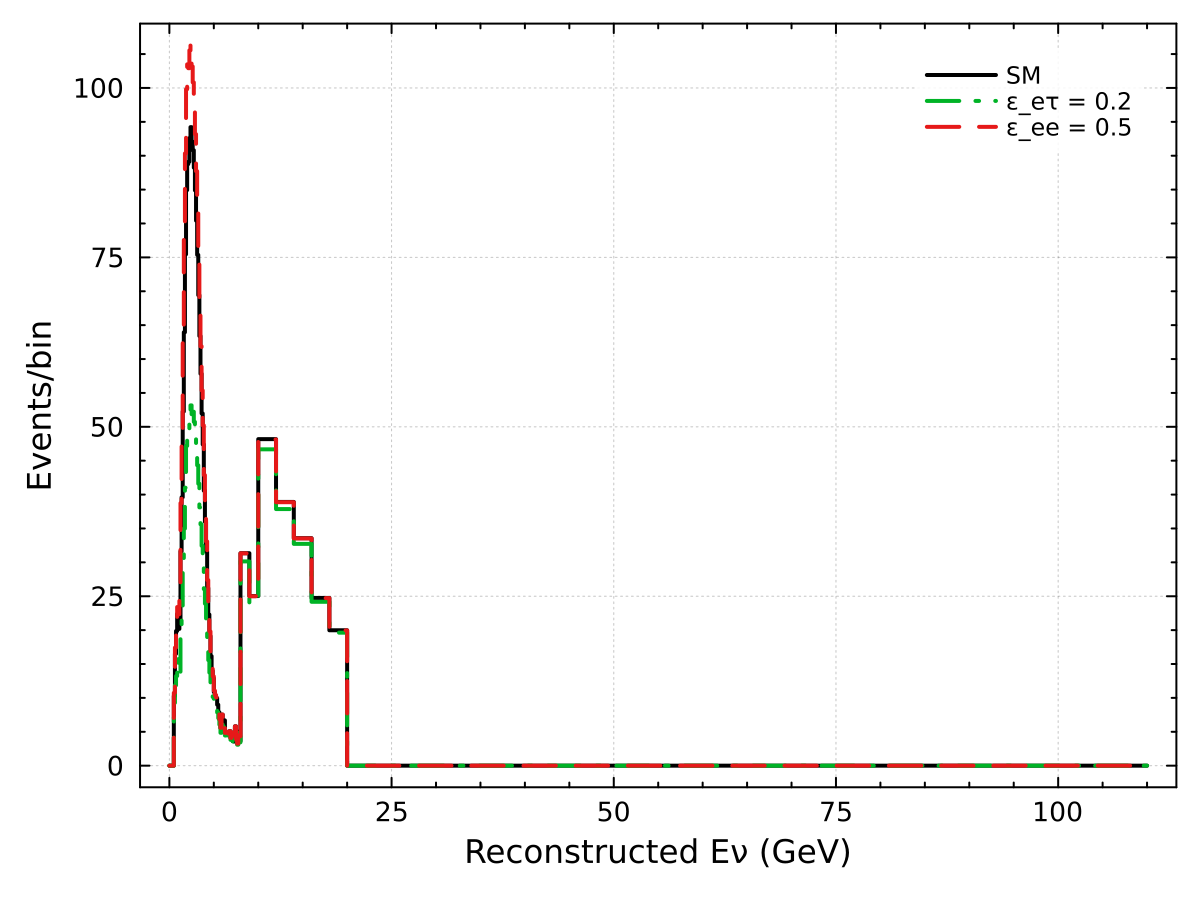

In [15]:
plot_events(dune, curves...; rule = 1)   # νe appearance

## How well DUNE measures ε_eτ

The data are simulated in the SM and each test value of ε_eτ (with δε_eτ = 0) is compared with them. Without a fit, the χ² only says how different the spectra are. With a fit over θ23, δ and Δm²31, part of the NSI effect is absorbed by the standard parameters and the sensitivity is weaker. Each fitted point takes about half a minute.

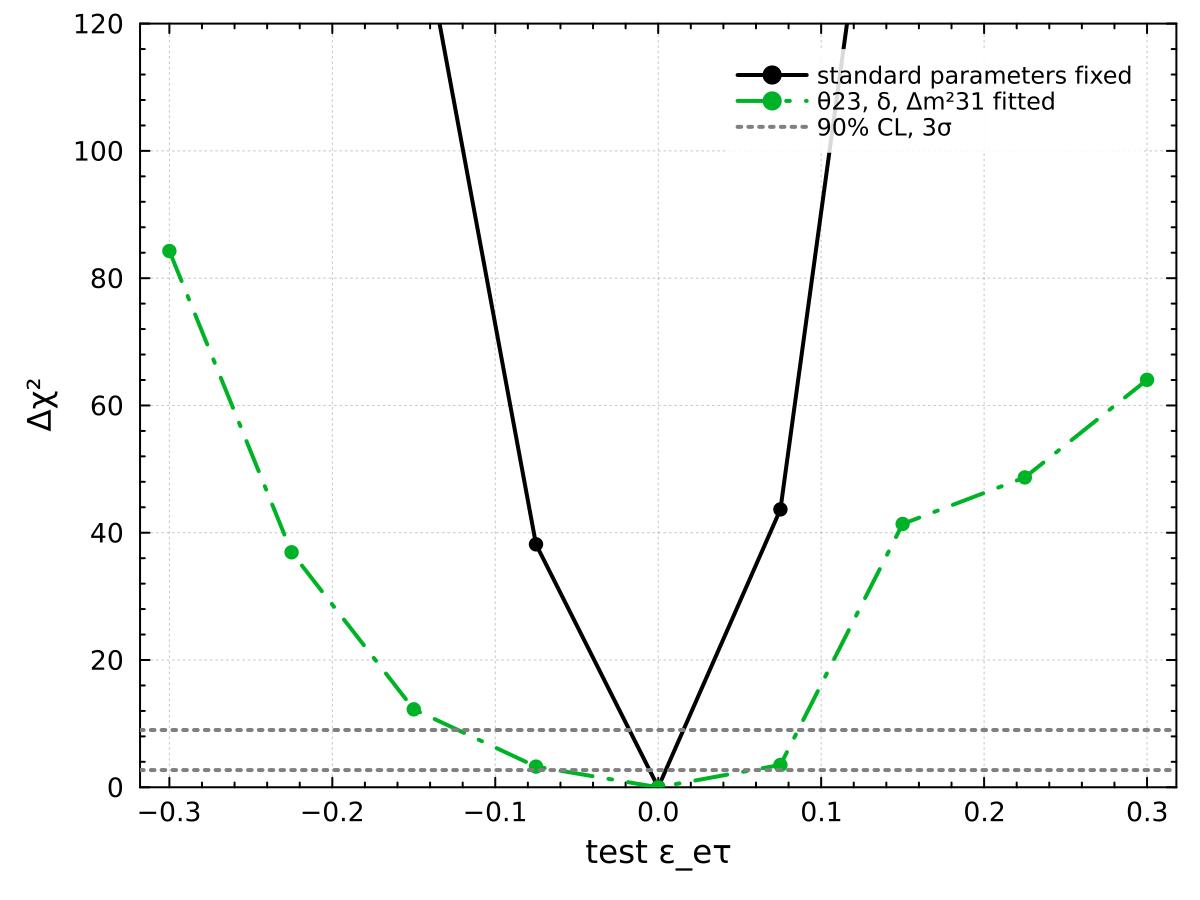

In [16]:
εs = range(-0.3, 0.3, 9)
fixed = chi2_profile(sm, :ε_eτ => εs)
fitted = chi2_profile(sm, :ε_eτ => εs; free = (:θ23, :δ, :Δm31))
plot_curves(εs, "standard parameters fixed" => fixed, "θ23, δ, Δm²31 fitted" => fitted; xlabel = "test ε_eτ", ylabel = "Δχ²", markers = true, ylims = (0, 120))
hline!([2.71, 9]; color = :gray, linestyle = :dot, label = "90% CL, 3σ")

## Writing your own block

NeutrinoVectorNSI.jl is itself one example of how to extend GLoBES.jl. Suppose a new interaction couples only to up quarks with strength ε^u_ee. In the Earth there are about 3 up quarks per electron, so its effective coupling is 3ε^u_ee. Two methods are enough:

In [17]:
struct UpQuarkNSI <: GLoBES.PropagationBlock end
GLoBES.block_parameters(::UpQuarkNSI) = [:εu_ee]
GLoBES.matter_correction!(ε, ::UpQuarkNSI, p, x) = (ε[1, 1] += 3 * x[:εu_ee]; ε)

combined = NewPhysics(UpQuarkNSI(), VectorNSI(:eτ))   # blocks combine
use_model!(combined)
mine = OscParams(combined, p; εu_ee = 0.1)
use_model!(model)
theirs = OscParams(model, p; ε_ee = 0.3)
use_model!(combined)
a = probability(mine, :μ, :e; E = Echeck, DUNE...)
use_model!(model)
maximum(abs, a .- probability(theirs, :μ, :e; E = Echeck, DUNE...))   # εu_ee = 0.1 is ε_ee = 0.3

0.0

In [18]:
standard_engine!()   # back to standard three-flavour oscillations